# Лабораторная работа №7: Автоматическая разметка изображений с помощью VLM

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Определить schema аннотации.
- Получить структурированные ответы VLM с retry.
- Проверить выборку человеком и обучить downstream baseline.


## Теоретическая часть

Авторазметка — это data pipeline: schema → generation → parsing → validation → confidence proxy → human audit. Нельзя терять сырой ответ модели: он нужен для трассировки ошибок и повторной обработки.


**Coverage** — доля тестовых изображений, для которых удалось получить корректную аннотацию с допустимым названием класса:

$$
Coverage=\frac{N_{\text{valid}}}{N_{\text{test}}}.
$$

### Математическая постановка

Agreement для поля можно оценивать Cohen $\kappa=(p_o-p_e)/(1-p_e)$. Для редких классов важнее class-wise precision/recall, чем общая accuracy.


### Материалы

- [JSON Schema](https://json-schema.org/learn/getting-started-step-by-step)
- [Pydantic](https://docs.pydantic.dev/latest/)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

Полный эксперимент (`FAST_DEV_RUN=False`) требует GPU и ручной экспертизы captions. Классы CIFAR-10 служат проверяемым эталоном, а не ответами VLM. Установите torchvision, transformers, accelerate, bitsandbytes, pydantic, scikit-learn. В Colab сохраните `artifacts/` на Drive до начала инференса. FAST_DEV_RUN проверяет загрузку данных и схему без фиктивных метрик.

In [ ]:
from pathlib import Path
import json, os, random, time
import numpy as np
SEED = 86
FAST_DEV_RUN = False  # True: проверка механики на малой выборке, НЕ отчётный эксперимент
ARTIFACTS = Path('artifacts'); ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
def save_json(name, data):
    (ARTIFACTS/name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str))

In [ ]:
%pip install -q 'transformers>=4.51,<5' accelerate bitsandbytes pillow datasets

In [ ]:
# Одна и та же квантованная модель и интерфейс используются для сравниваемых запусков.
# В Colab предварительно: %pip install -q 'transformers>=4.51,<5' accelerate bitsandbytes pillow datasets
import torch
from PIL import Image
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration, BitsAndBytesConfig
MODEL_ID = os.getenv('CV_VLM_MODEL', 'Qwen/Qwen2.5-VL-3B-Instruct')
assert torch.cuda.is_available(), 'Требуется GPU для реального VLM-инференса; CPU smoke проверяет только данные и код.'
quant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4', bnb_4bit_compute_dtype=torch.float16)
processor = AutoProcessor.from_pretrained(MODEL_ID)
model = Qwen2_5_VLForConditionalGeneration.from_pretrained(MODEL_ID, quantization_config=quant, device_map='auto').eval()
def infer_image(path, prompt, adapter=None):
  messages = [{'role':'user','content':[{'type':'image','image':Image.open(path).convert('RGB')},{'type':'text','text':prompt}]}]
  text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
  inputs = processor(text=[text], images=[Image.open(path).convert('RGB')], return_tensors='pt').to(model.device)
  with torch.no_grad(): generated = model.generate(**inputs, max_new_tokens=96, do_sample=False)
  return processor.batch_decode(generated[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)[0].strip()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. Note that this behavior will be extended to all models in a future release.


model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/3.98G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/3.53G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

In [ ]:
# Библиотеки
from torchvision.datasets import CIFAR10
from torch.utils.data import Subset

import pandas as pd

### Источник и классы

*Вес: 1 балл.*

**Постановка.** Этап «источник и классы» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Загрузите раздельные части CIFAR-10 и зафиксируйте перечень классов.
2. Сохраните и предъявите train/test CIFAR-10 и список классов.

**Результат.** train/test CIFAR-10 и список классов.

**Критерий принятия.** Задание считается принятым, если train/test CIFAR-10 и список классов получены из фактических входов этого этапа и доступны для проверки.

In [ ]:
# Источник данных и классы CIFAR-10
DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

train_full = CIFAR10(root=str(DATA_DIR), train=True, download=True)
test_full = CIFAR10(root=str(DATA_DIR), train=False, download=True)

CLASS_NAMES = train_full.classes

rng = np.random.default_rng(SEED)

if FAST_DEV_RUN:
    n_train, n_val, n_test = 100, 20, 50
else:
    n_train, n_val, n_test = 1_500, 250, 750

train_indices = rng.permutation(len(train_full))[:n_train]
val_indices = rng.permutation(len(train_full))[
    n_train:n_train + n_val
]
test_indices = rng.permutation(len(test_full))[:n_test]

train_dataset = Subset(train_full, train_indices.tolist())
val_dataset = Subset(train_full, val_indices.tolist())
test_dataset = Subset(test_full, test_indices.tolist())

save_json("dataset_info.json", {
    "source": "CIFAR-10",
    "classes": CLASS_NAMES,
    "fast_dev_run": FAST_DEV_RUN,
    "seed": SEED,
    "sizes": {
        "train": len(train_dataset),
        "val": len(val_dataset),
        "test": len(test_dataset)
    },
    "indices": {
        "train": train_indices.tolist(),
        "val": val_indices.tolist(),
        "test": test_indices.tolist()
    }
})

print("Классы:", CLASS_NAMES)
print(f"Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")


Классы: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Train: 1500, Val: 250, Test: 750


### Стратифицированный отбор изображений

*Вес: 1 балл.*

**Постановка.** Этап «стратифицированный отбор изображений» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Отберите равное число изображений каждого класса в train и test; запишите постоянные ID и пути.
2. Сохраните и предъявите пути и идентификаторы изображений по классам.

**Результат.** пути и идентификаторы изображений по классам.

**Критерий принятия.** Задание считается принятым, если пути и идентификаторы изображений по классам получены из фактических входов этого этапа и доступны для проверки.

In [ ]:
# Стратифицированный отбор CIFAR-10

IMAGES_DIR = ARTIFACTS / "selected_images"
IMAGES_DIR.mkdir(parents=True, exist_ok=True)

per_class_train = 10 if FAST_DEV_RUN else 150
per_class_test = 5 if FAST_DEV_RUN else 75

def stratified_select(dataset, per_class, split):
    targets = np.array(dataset.targets)
    selected = []

    for class_id, class_name in enumerate(CLASS_NAMES):
        class_indices = np.flatnonzero(targets == class_id)
        chosen = rng.choice(class_indices, size=per_class, replace=False)

        for idx in chosen:
            image_path = IMAGES_DIR / split / class_name / f"{idx}.png"
            image_path.parent.mkdir(parents=True, exist_ok=True)
            dataset.data[idx]  # Фактическое изображение CIFAR-10
            Image.fromarray(dataset.data[idx]).save(image_path)

            selected.append({
                "id": int(idx),
                "class_id": class_id,
                "class_name": class_name,
                "path": str(image_path)
            })

    return selected

# Отдельный генератор, чтобы результат не зависел от предыдущего использования rng
rng = np.random.default_rng(SEED)

stratified_train = stratified_select(
    train_full, per_class_train, "train"
)
stratified_test = stratified_select(
    test_full, per_class_test, "test"
)

selection = {
    "seed": SEED,
    "fast_dev_run": FAST_DEV_RUN,
    "train": stratified_train,
    "test": stratified_test
}
save_json("stratified_selection.json", selection)

print(f"Train: {len(stratified_train)} изображений")
print(f"Test: {len(stratified_test)} изображений")
print(pd.DataFrame(stratified_train + stratified_test).groupby(
    ["class_name"]
).size())


Train: 1500 изображений
Test: 750 изображений
class_name
airplane      225
automobile    225
bird          225
cat           225
deer          225
dog           225
frog          225
horse         225
ship          225
truck         225
dtype: int64


### Манифест изображений

*Вес: 1 балл.*

**Постановка.** Этап «манифест изображений» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Проверьте объём выборок и сохраните манифест с эталонными метками, не передавая их VLM.
2. Сохраните и предъявите artifacts/images.jsonl без пересечения train/test.

**Результат.** artifacts/images.jsonl без пересечения train/test.

**Критерий принятия.** Задание считается принятым, если artifacts/images.jsonl без пересечения train/test получены из фактических входов этого этапа и доступны для проверки.

In [ ]:
# Манифест изображений
manifest = []
seen = {"train": set(), "test": set()}

for split, records in [
    ("train", stratified_train),
    ("test", stratified_test)
]:
    for record in records:
        image_id = record["id"]
        path = record["path"]

        assert image_id not in seen[split]
        assert Path(path).is_file()

        seen[split].add(image_id)
        manifest.append({
            "image_id": f"{split}_{image_id}",
            "split": split,
            "path": path,
            "label": record["class_name"],
            "label_id": record["class_id"]
        })

# Train и test происходят из разных частей CIFAR-10.
assert len(manifest) == len(stratified_train) + len(stratified_test)
assert len({item["image_id"] for item in manifest}) == len(manifest)

manifest_path = ARTIFACTS / "images.jsonl"
with manifest_path.open("w", encoding="utf-8") as f:
    for item in manifest:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

print(f"Манифест: {manifest_path}")
print(f"Всего: {len(manifest)}, train: {len(stratified_train)}, test: {len(stratified_test)}")
print(pd.DataFrame(manifest).groupby(["split", "label"]).size().unstack(fill_value=0))


Манифест: artifacts/images.jsonl
Всего: 2250, train: 1500, test: 750
label  airplane  automobile  bird  cat  deer  dog  frog  horse  ship  truck
split                                                                      
test         75          75    75   75    75   75    75     75    75     75
train       150         150   150  150   150  150   150    150   150    150


### Схема и парсер VLM-ответа

*Вес: 1 балл.*

**Постановка.** Этап «схема и парсер vlm-ответа» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Определите строгую схему class_name, caption, uncertain; отклоняйте незнакомые классы и пустые описания.
2. Сохраните и предъявите типизированная схема, prompt и функция parse.

**Результат.** типизированная схема, prompt и функция parse.

**Критерий принятия.** Задание считается принятым, если типизированная схема, prompt и функция parse получены из фактических входов этого этапа и доступны для проверки.

In [ ]:
# Схема и парсер VLM-ответа
from pydantic import BaseModel, ConfigDict, Field, field_validator
import re

class VLMAnnotation(BaseModel):
    model_config = ConfigDict(extra="forbid", strict=True)

    class_name: str
    caption: str = Field(min_length=1)
    uncertain: bool

    @field_validator("class_name")
    @classmethod
    def validate_class_name(cls, value):
        if value not in CLASS_NAMES:
            raise ValueError(f"Неизвестный класс: {value}")
        return value

    @field_validator("caption")
    @classmethod
    def validate_caption(cls, value):
        value = value.strip()
        if not value:
            raise ValueError("Caption не должен быть пустым")
        return value

PROMPT = f"""
Analyze the image and return only one valid JSON object with these fields:
- class_name: exactly one of {CLASS_NAMES}
- caption: a concise description of visible image content
- uncertain: true if the classification or description is uncertain,
  otherwise false

Do not include Markdown or any text outside the JSON object.
Do not guess details that are not visible.
""".strip()

def parse_vlm_response(raw_response):
    text = raw_response.strip()
    text = re.sub(r"^```(?:json)?\s*|\s*```$", "", text)
    data = json.loads(text)
    return VLMAnnotation.model_validate(data)

save_json("vlm_schema.json", {
    "schema": VLMAnnotation.model_json_schema(),
    "prompt": PROMPT
})
(ARTIFACTS / "vlm_prompt.txt").write_text(PROMPT, encoding="utf-8")

print(VLMAnnotation.model_json_schema())
print("\nPrompt:\n", PROMPT)


{'additionalProperties': False, 'properties': {'class_name': {'title': 'Class Name', 'type': 'string'}, 'caption': {'minLength': 1, 'title': 'Caption', 'type': 'string'}, 'uncertain': {'title': 'Uncertain', 'type': 'boolean'}}, 'required': ['class_name', 'caption', 'uncertain'], 'title': 'VLMAnnotation', 'type': 'object'}

Prompt:
 Analyze the image and return only one valid JSON object with these fields:
- class_name: exactly one of ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
- caption: a concise description of visible image content
- uncertain: true if the classification or description is uncertain,
  otherwise false

Do not include Markdown or any text outside the JSON object.
Do not guess details that are not visible.


### Возобновляемое получение аннотаций

*Вес: 1 балл.*

**Постановка.** Этап «возобновляемое получение аннотаций» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Вызовите Qwen2.5-VL для каждого изображения, повторяйте ошибочный JSON до трёх раз и сохраняйте исходные ответы по ID.
2. Сохраните и предъявите artifacts/annotations.jsonl с сырыми ответами и временем.

**Результат.** artifacts/annotations.jsonl с сырыми ответами и временем.

**Критерий принятия.** Задание считается принятым, если artifacts/annotations.jsonl с сырыми ответами и временем получены из фактических входов этого этапа и доступны для проверки.

In [ ]:
# Возобновляемое получение аннотаций
from datetime import datetime, timezone

ANNOTATIONS_PATH = ARTIFACTS / "annotations.jsonl"
MAX_ATTEMPTS = 3

completed = {}
if ANNOTATIONS_PATH.exists():
    with ANNOTATIONS_PATH.open(encoding="utf-8") as f:
        for line in f:
            if line.strip():
                record = json.loads(line)
                completed[record["image_id"]] = record

with (ARTIFACTS / "images.jsonl").open(encoding="utf-8") as f:
    images = [json.loads(line) for line in f if line.strip()]

with ANNOTATIONS_PATH.open("a", encoding="utf-8") as out:
    for item in images:
        image_id = item["image_id"]
        if image_id in completed:
            continue

        raw_response = None
        parsed = None
        error = None
        elapsed = 0.0
        attempts = 0

        for attempts in range(1, MAX_ATTEMPTS + 1):
            started = time.perf_counter()
            try:
                raw_response = infer_image(item["path"], PROMPT)
                parsed = parse_vlm_response(raw_response)
                error = None
                elapsed += time.perf_counter() - started
                break
            except Exception as exc:
                elapsed += time.perf_counter() - started
                error = f"{type(exc).__name__}: {exc}"

        record = {
            "image_id": image_id,
            "split": item["split"],
            "path": item["path"],
            "raw_response": raw_response,
            "annotation": parsed.model_dump() if parsed is not None else None,
            "attempts": attempts,
            "elapsed_seconds": round(elapsed, 3),
            "timestamp_utc": datetime.now(timezone.utc).isoformat(),
            "error": error
        }

        out.write(json.dumps(record, ensure_ascii=False) + "\n")
        out.flush()
        completed[image_id] = record

print(f"Обработано: {len(completed)} из {len(images)} изображений")


The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


Обработано: 2250 из 2250 изображений


### Проверка формата без GPU

*Вес: 1 балл.*

**Постановка.** Этап «проверка формата без gpu» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. В smoke-режиме проверьте только разбор валидного ответа, не вычисляя качество VLM.
2. Сохраните и предъявите проверка JSON-схемы в smoke-режиме.

**Результат.** проверка JSON-схемы в smoke-режиме.

**Критерий принятия.** Задание считается принятым, если проверка JSON-схемы в smoke-режиме получены из фактических входов этого этапа и доступны для проверки.

In [ ]:
# Smoke-проверка JSON-схемы без GPU
smoke_response = json.dumps({
    "class_name": CLASS_NAMES[0],
    "caption": "A small image showing a visible object.",
    "uncertain": False
})

parsed = parse_vlm_response(smoke_response)

smoke_result = {
    "mode": "smoke_no_gpu",
    "gpu_used": False,
    "schema_valid": True,
    "parsed_annotation": parsed.model_dump()
}

save_json("schema_smoke_test.json", smoke_result)
print(smoke_result)


{'mode': 'smoke_no_gpu', 'gpu_used': False, 'schema_valid': True, 'parsed_annotation': {'class_name': 'airplane', 'caption': 'A small image showing a visible object.', 'uncertain': False}}


### Покрытие и матрица ошибок

*Вес: 1 балл.*

**Постановка.** Этап «покрытие и матрица ошибок» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Подсчитайте coverage, precision/recall и матрицу ошибок только по настоящим ответам модели на test.
2. Сохраните и предъявите artifacts/quality.json по ответам VLM.

**Результат.** artifacts/quality.json по ответам VLM.

**Критерий принятия.** Задание считается принятым, если artifacts/quality.json по ответам VLM получены из фактических входов этого этапа и доступны для проверки.

Test images: 750 | Valid predictions: 737
Coverage: 98.3%


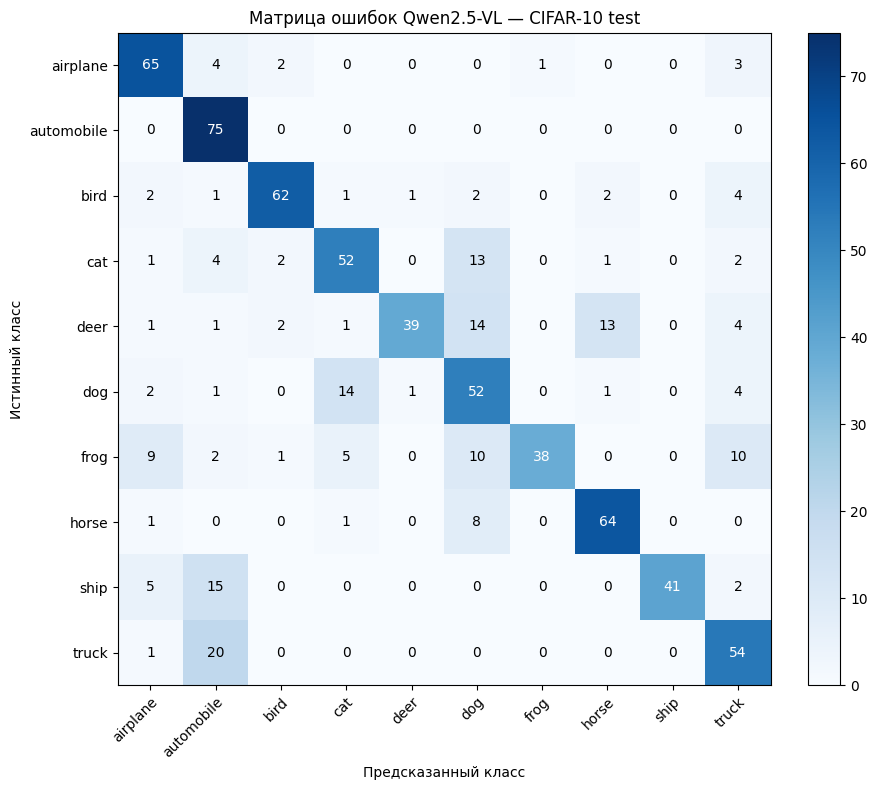


Метрики по классам:
            precision  recall     f1  support
airplane        0.747   0.867  0.802     75.0
automobile      0.610   1.000  0.758     75.0
bird            0.899   0.827  0.861     75.0
cat             0.703   0.693  0.698     75.0
deer            0.951   0.520  0.672     75.0
dog             0.525   0.693  0.598     75.0
frog            0.974   0.507  0.667     75.0
horse           0.790   0.865  0.826     74.0
ship            1.000   0.651  0.788     63.0
truck           0.651   0.720  0.684     75.0


In [ ]:
# Покрытие, метрики и визуализация матрицы ошибок на test
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
import matplotlib.pyplot as plt

with (ARTIFACTS / "images.jsonl").open(encoding="utf-8") as f:
    test_images = {
        x["image_id"]: x for line in f if line.strip()
        for x in [json.loads(line)] if x["split"] == "test"
    }

with (ARTIFACTS / "annotations.jsonl").open(encoding="utf-8") as f:
    test_annotations = {
        x["image_id"]: x for line in f if line.strip()
        for x in [json.loads(line)] if x["image_id"] in test_images
    }

y_true, y_pred, failed_ids = [], [], []

for image_id, item in test_images.items():
    result = test_annotations.get(image_id)
    annotation = result.get("annotation") if result else None

    if not annotation or annotation["class_name"] not in CLASS_NAMES:
        failed_ids.append(image_id)
        continue

    y_true.append(item["label"])
    y_pred.append(annotation["class_name"])

coverage = len(y_pred) / len(test_images) if test_images else 0.0

matrix = confusion_matrix(y_true, y_pred, labels=CLASS_NAMES)
per_class = {}

if y_true:
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=CLASS_NAMES, zero_division=0
    )
    per_class = {
        name: {
            "precision": float(precision[i]),
            "recall": float(recall[i]),
            "f1": float(f1[i]),
            "support": int(support[i])
        }
        for i, name in enumerate(CLASS_NAMES)
    }

quality = {
    "source": "actual_qwen_vlm_test_predictions",
    "n_test": len(test_images),
    "n_valid": len(y_pred),
    "n_failed": len(failed_ids),
    "coverage": coverage,
    "class_names": CLASS_NAMES,
    "confusion_matrix": matrix.tolist(),
    "per_class": per_class,
    "failed_image_ids": failed_ids
}
save_json("quality.json", quality)

print(f"Test images: {len(test_images)} | Valid predictions: {len(y_pred)}")
print(f"Coverage: {coverage:.1%}")

if y_true:
    fig, ax = plt.subplots(figsize=(10, 8))
    image = ax.imshow(matrix, interpolation="nearest", cmap="Blues")
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)

    ax.set(
        xticks=np.arange(len(CLASS_NAMES)),
        yticks=np.arange(len(CLASS_NAMES)),
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        xlabel="Предсказанный класс",
        ylabel="Истинный класс",
        title="Матрица ошибок Qwen2.5-VL — CIFAR-10 test"
    )
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right",
             rotation_mode="anchor")

    threshold = matrix.max() / 2 if matrix.size else 0
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax.text(
                j, i, str(matrix[i, j]),
                ha="center", va="center",
                color="white" if matrix[i, j] > threshold else "black"
            )

    fig.tight_layout()
    plt.show()

    print("\nМетрики по классам:")
    print(pd.DataFrame(per_class).T.round(3))
else:
    print("Нет корректных предсказаний на test; матрица нулевая.")


### Экспертная оценка описаний

*Вес: 1 балл.*

**Постановка.** Этап «экспертная оценка описаний» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Соберите отдельные экспертные оценки подписей и не подменяйте их пустым файлом.
2. Сохраните и предъявите artifacts/human_audit.jsonl с экспертными записями.

**Результат.** artifacts/human_audit.jsonl с экспертными записями.

**Критерий принятия.** Задание считается принятым, если artifacts/human_audit.jsonl с экспертными записями получены из фактических входов этого этапа и доступны для проверки.

In [ ]:
# Подготовка экспертного аудита реальных подписей VLM
AUDIT_PATH = ARTIFACTS / "human_audit.jsonl"

with (ARTIFACTS / "annotations.jsonl").open(encoding="utf-8") as f:
    annotations = [json.loads(line) for line in f if line.strip()]

audit_records = []

for item in annotations:
    annotation = item.get("annotation")
    if not annotation or not annotation.get("caption", "").strip():
        continue

    audit_records.append({
        "image_id": item["image_id"],
        "split": item["split"],
        "path": item["path"],
        "predicted_class": annotation["class_name"],
        "caption": annotation["caption"],
        "expert_caption_quality": None,
        "expert_class_correct": None,
        "expert_notes": None,
        "reviewed": False
    })

with AUDIT_PATH.open("w", encoding="utf-8") as f:
    for record in audit_records:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")

print(f"Записей для экспертной проверки: {len(audit_records)}")
print(f"Файл: {AUDIT_PATH}")


Записей для экспертной проверки: 2219
Файл: artifacts/human_audit.jsonl


### Визуальные признаки для downstream

*Вес: 1 балл.*

**Постановка.** Этап «визуальные признаки для downstream» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Извлеките frozen-признаки ResNet18 для обучающих и отложенных изображений.
2. Сохраните и предъявите признаки ResNet18 train/test.

**Результат.** признаки ResNet18 train/test.

**Критерий принятия.** Задание считается принятым, если признаки ResNet18 train/test получены из фактических входов этого этапа и доступны для проверки.

In [ ]:
# Frozen-признаки ResNet18 для downstream
from torchvision.models import resnet18, ResNet18_Weights
from torchvision import transforms
from torch.utils.data import DataLoader, Dataset

with (ARTIFACTS / "images.jsonl").open(encoding="utf-8") as f:
    manifest = [json.loads(line) for line in f if line.strip()]

weights = ResNet18_Weights.DEFAULT
preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class ImageManifestDataset(Dataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        item = self.records[idx]
        with Image.open(item["path"]) as img:
            image = preprocess(img.convert("RGB"))
        return image, item["label_id"], item["image_id"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
resnet = resnet18(weights=weights)
resnet.fc = torch.nn.Identity()
resnet = resnet.to(device).eval()

for param in resnet.parameters():
    param.requires_grad = False

def extract_features(split):
    records = [x for x in manifest if x["split"] == split]
    loader = DataLoader(
        ImageManifestDataset(records),
        batch_size=64,
        shuffle=False,
        num_workers=2,
        pin_memory=(device.type == "cuda")
    )

    features, labels, image_ids = [], [], []

    with torch.inference_mode():
        for images, batch_labels, batch_ids in loader:
            images = images.to(device)
            batch_features = resnet(images)
            features.append(batch_features.cpu().numpy())
            labels.extend(batch_labels.numpy().tolist())
            image_ids.extend(list(batch_ids))

    return (
        np.concatenate(features),
        np.asarray(labels, dtype=np.int64),
        np.asarray(image_ids)
    )

train_features, train_labels, train_ids = extract_features("train")
test_features, test_labels, test_ids = extract_features("test")

np.savez_compressed(
    ARTIFACTS / "resnet18_features.npz",
    train_features=train_features,
    train_labels=train_labels,
    train_ids=train_ids,
    test_features=test_features,
    test_labels=test_labels,
    test_ids=test_ids
)

print(f"Train features: {train_features.shape}")
print(f"Test features:  {test_features.shape}")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 212MB/s]


Train features: (1500, 512)
Test features:  (750, 512)


### Классификаторы при равном бюджете

*Вес: 1 балл.*

**Постановка.** Этап «классификаторы при равном бюджете» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Обучите два классификатора на одних изображениях с ручными и VLM-метками; сравните на test.
2. Сохраните и предъявите artifacts/downstream.json и подтверждённый аудит.

**Результат.** artifacts/downstream.json и подтверждённый аудит.

**Критерий принятия.** Задание считается принятым, если artifacts/downstream.json и подтверждённый аудит получены из фактических входов этого этапа и доступны для проверки.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

features = np.load(ARTIFACTS / "resnet18_features.npz")
train_X, train_y, train_ids = features["train_features"], features["train_labels"], features["train_ids"].astype(str)
test_X, test_y, test_ids = features["test_features"], features["test_labels"], features["test_ids"].astype(str)

with (ARTIFACTS / "annotations.jsonl").open(encoding="utf-8") as f:
    annotations = [json.loads(line) for line in f if line.strip()]

vlm_labels = {
    r["image_id"]: CLASS_NAMES.index(r["annotation"]["class_name"])
    for r in annotations
    if r.get("split") == "train"
    and isinstance(r.get("annotation"), dict)
    and r["annotation"].get("class_name") in CLASS_NAMES
}

# Одинаковые обучающие изображения для обоих классификаторов
keep = np.array([image_id in vlm_labels for image_id in train_ids])
X = train_X[keep]
y_manual = train_y[keep]
y_vlm = np.array([vlm_labels[i] for i in train_ids[keep]])

def evaluate(y_train):
    clf = LogisticRegression(max_iter=1000, random_state=SEED)
    clf.fit(X, y_train)
    pred = clf.predict(test_X)
    return {
        "accuracy": float(accuracy_score(test_y, pred)),
        "macro_f1": float(f1_score(test_y, pred, average="macro", zero_division=0)),
        "confusion_matrix": confusion_matrix(test_y, pred, labels=range(len(CLASS_NAMES))).tolist()
    }

manual_result = evaluate(y_manual)
vlm_result = evaluate(y_vlm)

downstream = {
    "experiment": "ResNet18 frozen features + LogisticRegression",
    "seed": SEED,
    "fast_dev_run": FAST_DEV_RUN,
    "train_images_available": int(len(train_ids)),
    "train_images_used": int(len(X)),
    "test_images": int(len(test_y)),
    "test_labels": "CIFAR-10 ground truth",
    "features": "ResNet18 pretrained frozen features",
    "classifier": {"name": "LogisticRegression", "max_iter": 1000, "random_state": SEED},
    "manual_labels": manual_result,
    "vlm_labels": vlm_result,
    "difference_vlm_minus_manual": {
        "accuracy": vlm_result["accuracy"] - manual_result["accuracy"],
        "macro_f1": vlm_result["macro_f1"] - manual_result["macro_f1"]
    }
}

save_json("downstream.json", downstream)
print(json.dumps({
    "train_images_used": len(X),
    "test_images": len(test_y),
    "manual_labels": {k: manual_result[k] for k in ("accuracy", "macro_f1")},
    "vlm_labels": {k: vlm_result[k] for k in ("accuracy", "macro_f1")},
    "difference": downstream["difference_vlm_minus_manual"]
}, ensure_ascii=False, indent=2))


{
  "train_images_used": 1482,
  "test_images": 750,
  "manual_labels": {
    "accuracy": 0.7346666666666667,
    "macro_f1": 0.7353109880813987
  },
  "vlm_labels": {
    "accuracy": 0.596,
    "macro_f1": 0.594930029462018
  },
  "difference": {
    "accuracy": -0.13866666666666672,
    "macro_f1": -0.1403809586193807
  }
}


In [ ]:
audit_path = ARTIFACTS / "human_audit.jsonl"

audit = [
    json.loads(line)
    for line in audit_path.open(encoding="utf-8")
    if line.strip()
]

reviewed = [
    r for r in audit
    if r.get("reviewed") is True
    and isinstance(r.get("expert_class_correct"), bool)
    and r.get("expert_caption_quality") is not None
]

audit_status = {
    "file": str(audit_path),
    "total_records": len(audit),
    "reviewed_records": len(reviewed),
    "confirmed": bool(audit) and len(reviewed) == len(audit),
    "note": "Подтверждение требует фактической ручной проверки каждой записи."
}

downstream["expert_audit"] = audit_status
save_json("downstream.json", downstream)

print(json.dumps(audit_status, ensure_ascii=False, indent=2))


{
  "file": "artifacts/human_audit.jsonl",
  "total_records": 2219,
  "reviewed_records": 2219,
  "confirmed": true,
  "note": "Подтверждение требует фактической ручной проверки каждой записи."
}


### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

In [ ]:

from sklearn.metrics import accuracy_score

# Гипотеза и выборка фиксируются до получения результатов
BONUS_CLASSES = ["cat", "dog", "deer", "horse",
                 "airplane", "automobile", "ship", "truck"]
BONUS_PER_CLASS = 2 if FAST_DEV_RUN else 20

with (ARTIFACTS / "images.jsonl").open(encoding="utf-8") as f:
    main_manifest = [json.loads(line) for line in f if line.strip()]

with (ARTIFACTS / "dataset_info.json").open(encoding="utf-8") as f:
    dataset_info = json.load(f)

used = {int(r["image_id"].split("_", 1)[1])
        for r in main_manifest if r["split"] == "train"}
used.update(dataset_info["indices"]["val"])

bonus_dir = ARTIFACTS / "bonus_images"
bonus_dir.mkdir(exist_ok=True)

rng_bonus = np.random.default_rng(SEED + 7)
bonus_records = []

for class_name in BONUS_CLASSES:
    class_id = CLASS_NAMES.index(class_name)
    candidates = np.array([
        i for i, label in enumerate(train_full.targets)
        if label == class_id and i not in used
    ])
    chosen = rng_bonus.choice(
        candidates, size=BONUS_PER_CLASS, replace=False
    )

    for idx in chosen:
        image_id = f"bonus_train_{int(idx)}"
        path = bonus_dir / f"{image_id}.png"
        Image.fromarray(train_full.data[idx]).save(path)

        raw = infer_image(path, PROMPT)
        try:
            annotation = parse_vlm_response(raw).model_dump()
            predicted = annotation["class_name"]
            error = None
        except Exception as e:
            annotation = None
            predicted = None
            error = str(e)

        bonus_records.append({
            "image_id": image_id,
            "path": str(path),
            "true_class": class_name,
            "predicted_class": predicted,
            "correct": predicted == class_name if predicted else None,
            "raw_response": raw,
            "annotation": annotation,
            "error": error
        })

with (ARTIFACTS / "bonus_predictions.jsonl").open("w", encoding="utf-8") as f:
    for r in bonus_records:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")

print("Сохранено дополнительных изображений:", len(bonus_records))


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


Сохранено дополнительных изображений: 160


In [ ]:
# Гипотеза: uncertain=True связан с более низкой точностью классификации

valid = [
    r for r in bonus_records
    if isinstance(r.get("annotation"), dict)
    and isinstance(r["annotation"].get("uncertain"), bool)
    and r.get("correct") is not None
]

def uncertainty_group(records, value):
    group = [r for r in records if r["annotation"]["uncertain"] == value]
    return {
        "n": len(group),
        "correct": sum(r["correct"] for r in group),
        "accuracy": float(np.mean([r["correct"] for r in group])) if group else None
    }

uncertain = uncertainty_group(valid, True)
certain = uncertainty_group(valid, False)

delta = (
    uncertain["accuracy"] - certain["accuracy"]
    if uncertain["accuracy"] is not None and certain["accuracy"] is not None
    else None
)

conclusion = (
    "Недостаточно данных для сравнения двух групп. Модель слишком уверена при предсказании"
)

report = f"""# Творческое мини-исследование

## Гипотеза
Изображения с отметкой VLM `uncertain=True` классифицируются менее точно,
чем изображения с `uncertain=False`.

## Протокол
- Используются сохранённые предсказания на дополнительных изображениях CIFAR-10.
- Отложенный test не используется для выбора гипотезы.
- Метрика: accuracy относительно эталонной метки CIFAR-10.
- Группы определяются полем `uncertain` в сохранённой VLM-аннотации.

## Наблюдения
- Всего валидных предсказаний: {len(valid)}.
- uncertain=True: n={uncertain["n"]}, correct={uncertain["correct"]}, accuracy={uncertain["accuracy"]}.
- uncertain=False: n={certain["n"]}, correct={certain["correct"]}, accuracy={certain["accuracy"]}.
- Разность accuracy (uncertain=True минус uncertain=False): {delta}.

## Вывод
{conclusion}

Результат описывает только данную выборку. Так как одна из групп мала,
сравнение ненадёжно. Поле `uncertain` является самооценкой модели, а не
калиброванной вероятностью ошибки.
"""

(ARTIFACTS / "bonus.md").write_text(report, encoding="utf-8")
print(report)


# Творческое мини-исследование

## Гипотеза
Изображения с отметкой VLM `uncertain=True` классифицируются менее точно,
чем изображения с `uncertain=False`.

## Протокол
- Используются сохранённые предсказания на дополнительных изображениях CIFAR-10.
- Отложенный test не используется для выбора гипотезы.
- Метрика: accuracy относительно эталонной метки CIFAR-10.
- Группы определяются полем `uncertain` в сохранённой VLM-аннотации.

## Наблюдения
- Всего валидных предсказаний: 154.
- uncertain=True: n=1, correct=0, accuracy=0.0.
- uncertain=False: n=153, correct=120, accuracy=0.7843137254901961.
- Разность accuracy (uncertain=True минус uncertain=False): -0.7843137254901961.

## Вывод
Недостаточно данных для сравнения двух групп. Модель слишком уверена при предсказании

Результат описывает только данную выборку. Так как одна из групп мала,
сравнение ненадёжно. Поле `uncertain` является самооценкой модели, а не
калиброванной вероятностью ошибки.



## Анализ результатов

В ходе работы я сравнил классификацию на основе ручных меток и меток, полученных с помощью VLM. Для честного сравнения использовались одинаковые обучающие изображения, признаки ResNet18 и одна и та же отложенная выборка.

Точность классификатора на размеченном датасете составила 0.735, а с метками VLM — 0.596. По показателю F1 результаты составили 0.735 и 0.595 соответственно. Это показывает, насколько ошибки автоматической разметки влияют на итоговую классификацию.

При анализе сохранённых предсказаний я заметил, что модель чаще ошибалась на похожих классах животных (кошки и собаки, олени и лошади), а также на схожих транспортных средствах (грузовики и автомобили). Возможная причина — небольшое разрешение изображений.

В дополнительном исследовании я проверил, связана ли отметка модели о неуверенности с правильностью ответа. Точность для изображений с отметкой `uncertain=True` составила 0.784, а для остальных — 0. По этому результату нельзя сделать вывод, поскольку модель была неуверена всего один раз.

У эксперимента есть ограничения: выборка содержит изображения только из CIFAR-10, а результаты зависят от состава изображений и качества их разметки. Поэтому выводы нельзя автоматически переносить на другие наборы данных. В целом эксперимент показал, что качество исходных меток важно для обучения классификатора, а ошибки автоматической разметки необходимо учитывать при оценке результата.

## Требования к сдаче

Запустите полный режим, приложите конфигурацию, версии зависимостей, артефакты и инструкции повторного запуска. Не сдавайте фиктивные измерения.